In [2]:

import pandas as pd
from google.colab import files

uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(filename)

print("Food Delivery Data Analysis")
print("Dataset Shape:", df.shape)
display(df.head())


Saving food_delivery_orders.csv to food_delivery_orders.csv
Food Delivery Data Analysis
Dataset Shape: (200, 13)


,Order_ID,Order_Date,Customer_ID,Restaurant,Cuisine,Area,Order_Amount_INR,Delivery_Fee_INR,Payment_Method,Distance_KM,Delivery_Time_Min,Customer_Rating,Order_Status
0,FD0001,2026-01-29,C055,Noodle House,Chinese,Anna Nagar,454.89,0,UPI,3.7,28,5,Delivered
1,FD0002,2026-02-25,C070,Spice Hub,Indian,Adyar,321.96,15,UPI,7.6,40,5,Delivered
2,FD0003,2026-05-31,C044,Burger Bay,Fast Food,Anna Nagar,304.48,20,UPI,9.3,46,4,Delivered
3,FD0004,2026-01-25,C069,Burger Bay,Fast Food,Anna Nagar,304.48,20,Card,7.6,42,5,Delivered
4,FD0005,2026-05-22,C030,Spice Hub,Indian,T. Nagar,757.92,20,UPI,7.8,42,5,Delivered


In [3]:

import pandas as pd
import matplotlib.pyplot as plt

# Food Delivery Data Analysis

delivered = df[df["Order_Status"] == "Delivered"]

print("TOTAL ORDERS:", len(df))
print("DELIVERED ORDERS:", len(delivered))
print("CANCELLED ORDERS:", (df["Order_Status"] == "Cancelled").sum())

print("DELIVERY RATE (%):",
      round(len(delivered) / len(df) * 100, 2))

print("TOTAL REVENUE (INR):",
      round(delivered["Order_Amount_INR"].sum(), 2))

print("AVERAGE ORDER VALUE (INR):",
      round(delivered["Order_Amount_INR"].mean(), 2))

print("AVERAGE DELIVERY TIME (MINUTES):",
      round(delivered["Delivery_Time_Min"].mean(), 2))

print("AVERAGE CUSTOMER RATING:",
      round(delivered["Customer_Rating"].mean(), 2))



TOTAL ORDERS: 200
DELIVERED ORDERS: 192
CANCELLED ORDERS: 8
DELIVERY RATE (%): 96.0
TOTAL REVENUE (INR): 74621.87
AVERAGE ORDER VALUE (INR): 388.66
AVERAGE DELIVERY TIME (MINUTES): 34.68
AVERAGE CUSTOMER RATING: 4.26


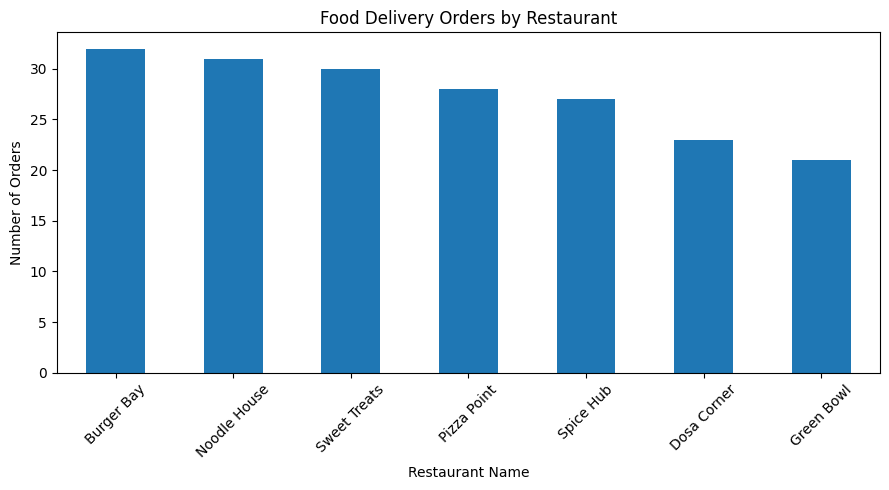

In [4]:

delivered["Restaurant"].value_counts().plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Food Delivery Orders by Restaurant")
plt.xlabel("Restaurant Name")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


/tmp/ipykernel_6069/506476044.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  delivered["Order_Date"] = pd.to_datetime(delivered["Order_Date"])
/tmp/ipykernel_6069/506476044.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  delivered["Month"] = delivered["Order_Date"].dt.to_period("M").astype(str)


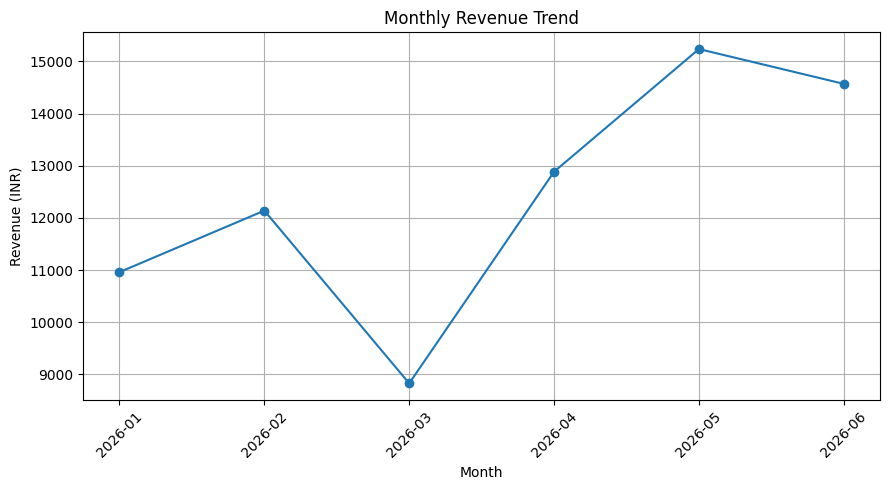

In [5]:

# Monthly Revenue Analysis

delivered["Order_Date"] = pd.to_datetime(delivered["Order_Date"])

delivered["Month"] = delivered["Order_Date"].dt.to_period("M").astype(str)

monthly_revenue = delivered.groupby("Month")["Order_Amount_INR"].sum()

monthly_revenue.plot(kind="line", marker="o", figsize=(9, 5))

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


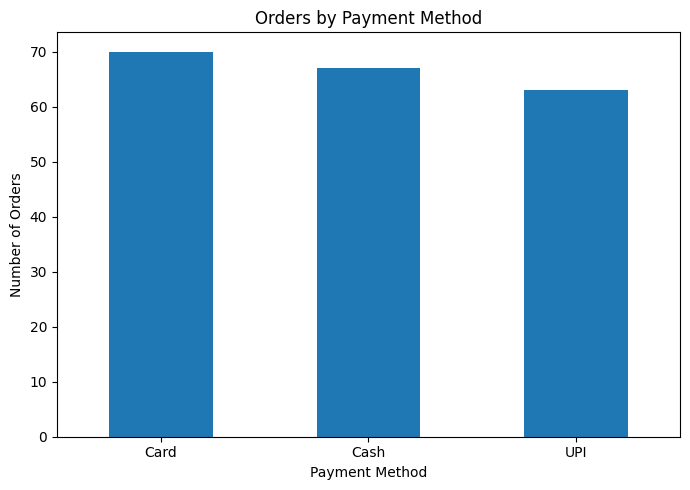

In [6]:

# Payment Method Analysis

df["Payment_Method"].value_counts().plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Orders by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


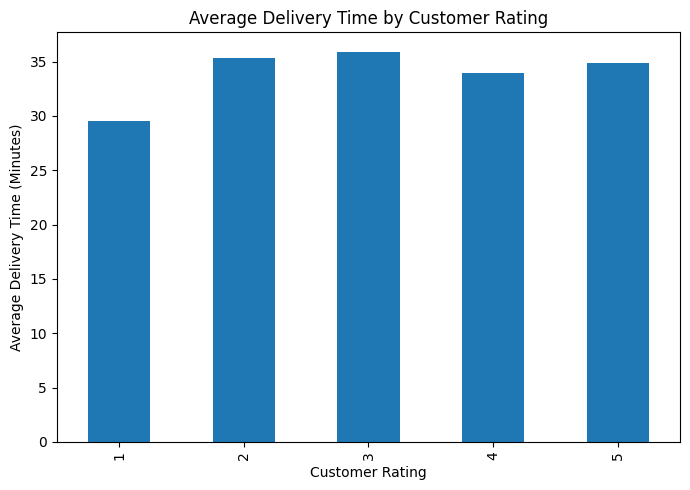

In [7]:

# Customer Rating Analysis

delivered.groupby("Customer_Rating")["Delivery_Time_Min"].mean().plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Average Delivery Time by Customer Rating")
plt.xlabel("Customer Rating")
plt.ylabel("Average Delivery Time (Minutes)")
plt.tight_layout()
plt.show()


In [8]:

# Final Food Delivery Analysis Summary

print("===== FOOD DELIVERY SERVICE ANALYSIS =====")

print("\n1. TOP RESTAURANTS")
print(delivered["Restaurant"].value_counts().head(3))

print("\n2. PAYMENT METHOD PREFERENCE")
print(df["Payment_Method"].value_counts())

print("\n3. CUISINE-WISE ORDERS")
print(delivered["Cuisine"].value_counts())

print("\n4. AREA-WISE ORDERS")
print(delivered["Area"].value_counts())

print("\n5. CUSTOMER RATINGS")
print(delivered["Customer_Rating"].value_counts().sort_index())

print("\n6. CANCELLED ORDER COUNT")
print((df["Order_Status"] == "Cancelled").sum())

print("\n===== ANALYSIS COMPLETED =====")


===== FOOD DELIVERY SERVICE ANALYSIS =====

1. TOP RESTAURANTS
Restaurant
Burger Bay      32
Noodle House    31
Sweet Treats    30
Name: count, dtype: int64

2. PAYMENT METHOD PREFERENCE
Payment_Method
Card    70
Cash    67
UPI     63
Name: count, dtype: int64

3. CUISINE-WISE ORDERS
Cuisine
Fast Food       32
Chinese         31
Dessert         30
Italian         28
Indian          27
South Indian    23
Healthy         21
Name: count, dtype: int64

4. AREA-WISE ORDERS
Area
T. Nagar      45
Anna Nagar    35
Tambaram      30
Porur         30
Velachery     27
Adyar         25
Name: count, dtype: int64

5. CUSTOMER RATINGS
Customer_Rating
1     2
2    11
3    21
4    59
5    99
Name: count, dtype: int64

6. CANCELLED ORDER COUNT
8

===== ANALYSIS COMPLETED =====
